# What does a score of 0.7 mean?

*Three embedding models, the same products, the same human judgements: where each one's relevance threshold actually sits.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/omnifroodle/couchbase_notebooks/blob/main/notebooks/retrieval/04_what_a_score_means.ipynb)
[![Open in GitHub Codespaces](https://img.shields.io/badge/Open%20in%20Codespaces-2f363d?logo=github&logoColor=white)](https://codespaces.new/omnifroodle/couchbase_notebooks?quickstart=1)

**Claim.** A similarity threshold belongs to one model, and it can be measured instead of guessed. Some human judgements, a few dozen questions the corpus cannot answer, and some SQL++ over logged hits give each model its own band.
**Result.** On 40 judged shopping queries and 41 unanswerable questions, the tutorial's 0.7 left between 15 and 31 of the queries with no results, depending on the model. A band chosen per model on half the questions kept nearly all of the right answers on the other half. One model's scores for answerable and unanswerable questions overlap, so no cut separates them cleanly, and dropping its query instruction moved its whole band up by about 0.25. Couchbase's approximate vector search missed the nearest product for many of the unanswerable questions and almost none of the answerable ones, which makes a model look better separated than it is.
**Requires.** couchbase · local-embeddings · api-embeddings
**Read** ~15 min · **Run** ~5 min · **Cost** under $0.01 — embeddings only, no chat model

Most retrieval tutorials end the same way. The search returns hits with scores, and a line
like `hits = [h for h in hits if h.score >= 0.7]` keeps the good ones. Below the line, nothing
is relevant; above it, everything is. Then the tutorial moves on, and nobody checks where the
0.7 came from.

It came from nowhere. A cosine similarity is a property of one model's geometry, not of
relevance. Two models that rank the same products in the same order can put them at 0.35 or at
0.75. So a fixed threshold is really a **calibration of one model**, usually done by guessing,
and it silently breaks the day the model changes.

This notebook measures that threshold instead of guessing it. It runs three embedding models
over the same 6,482 products, asks each the same 40 shopping queries a human judged, and adds
41 questions that a furniture catalogue cannot answer. Then it reads the scores the way a
filter has to read them, one model at a time.

**What this notebook does**

1. Embeds the products with three models, every model's vector on one Couchbase document.
2. Applies the tutorial threshold to every model, and shows what it does.
3. Scores the rankings with `trec_eval`, to separate *ranks well* from *scores well*.
4. Logs every hit as a document and reads the score distributions with SQL++.
5. Chooses a band for each model from those distributions, and checks it on questions it never saw.
6. Fits a mapping from score to probability, so a confidence means the same thing whichever model produced it.
7. Shows how the band moves when you shorten the vectors or drop the model's instructions.

In [ ]:
# Setup: load the helpers, install anything missing, check what this notebook needs.
import os
import pathlib
import subprocess
import sys

# Cloned on Colab, where there is no local checkout. Override to test a fork.
REPO_URL = os.environ.get("CBNB_REPO_URL", "https://github.com/omnifroodle/couchbase_notebooks")

try:
    import cbnb
except ModuleNotFoundError:
    here = pathlib.Path.cwd()
    root = next((p for p in [here, *here.parents] if (p / "cbnb" / "__init__.py").exists()), None)
    if root is None:
        # Colab: clone the repo so the committed datasets come with it. Once: a
        # restarted session keeps the files but not sys.path.
        root = pathlib.Path("cbnb-repo").resolve()
        if not root.exists():
            subprocess.check_call(["git", "clone", "--depth", "1", "--quiet", REPO_URL, str(root)])
    sys.path.insert(0, str(root))
    import cbnb

settings = cbnb.bootstrap(requires=["couchbase", "local-embeddings", "api-embeddings"],
                          extras=["metrics", "plots", "calibration"])

## 1. Questions with answers, and questions without

A threshold has two jobs. It must drop the hits that are wrong for a real question, and it must
drop *everything* for a question the corpus cannot answer. Measuring it needs evidence for both.

**For the first job**, the WANDS benchmark from [`retrieval/02`](02_which_parts_helped.ipynb):
40 real shopping queries, the 6,482 products judged for them, and 6,890 human judgements, each
`Exact`, `Partial` or `Irrelevant`. The `Irrelevant` judgements matter most here. They are not
random products: a person looked at each one because a search engine had offered it for that
query, and found it wrong. Those near misses are what a threshold has to reject. WANDS is
MIT-licensed. Many of the benchmarks usually used for this (SciFact, NFCorpus, FiQA) are
licensed for non-commercial research only.

**For the second job**, 41 questions from another dataset entirely: the clause questions from
[CUAD](https://www.atticusprojectai.org/cuad), the contract corpus behind
[`flows/01`](../flows/01_rag_that_you_can_trust.ipynb). *"Who are the parties to this
agreement?"* has no answer in a furniture catalogue. Each of these questions was written for
another system, so none of them was chosen to make this one look good or bad.

**To run this on your own corpus**, replace the next cell. Everything after it reads three
tables and nothing else:

| table | columns |
| --- | --- |
| `documents` | `doc_id`, `text`: what gets embedded and searched |
| `questions` | `question_id`, `text`, `on_topic`: `False` for questions your corpus cannot answer |
| `judgements` | `question_id`, `doc_id`, `label`: `Exact`, `Partial` or `Irrelevant` |

Judgements with only two grades map to `Exact` and `Irrelevant`. Off-topic questions can come
from anywhere your corpus has no answer: a log of searches that found nothing, or another
dataset, as here.

In [2]:
# Build the three input tables: documents, questions (on- and off-topic), and judgements.
import pandas as pd

from cbnb.datasets import load_cuad, load_wands_eval_set

pd.set_option("display.max_colwidth", 80)

evalset = load_wands_eval_set()
# The same thin text retrieval/01-03 index: a product's name and its class.
documents = pd.DataFrame({
    "doc_id": evalset.products.product_id.astype(str),
    "text": (evalset.products.product_name.fillna("") + " "
             + evalset.products.product_class.fillna("")).str.strip(),
})

off_topic = load_cuad().categories
questions = pd.concat([
    pd.DataFrame({"question_id": "q" + evalset.queries.query_id.astype(str),
                  "text": evalset.queries["query"], "on_topic": True}),
    pd.DataFrame({"question_id": [f"x{i}" for i in range(len(off_topic))],
                  "text": off_topic.question, "on_topic": False}),
], ignore_index=True)

# A few pairs were judged twice; keep the later verdict, as trec_eval's qrels would.
judgements = (pd.DataFrame({"question_id": "q" + evalset.labels.query_id.astype(str),
                            "doc_id": evalset.labels.product_id.astype(str),
                            "label": evalset.labels.label})
              .drop_duplicates(["question_id", "doc_id"], keep="last"))

pd.DataFrame({"rows": [len(documents), questions.on_topic.sum(), (~questions.on_topic).sum(), len(judgements)]},
             index=["documents", "on-topic questions", "off-topic questions", "judgements"])

,rows
documents,6482
on-topic questions,40
off-topic questions,41
judgements,6890


## 2. The candidates, one document

The models are the part of this notebook you are meant to change. Put in the ones you are
choosing between. The method does not care which they are. Three deliberately different ones
are here by default:

| | runs | input markup | can be shortened |
| --- | --- | --- | --- |
| **all-MiniLM-L6-v2** | on this machine | none | no |
| **Qwen3-Embedding** | your model provider | a task instruction before every query; documents plain | yes |
| **text-embedding-3-small** | your model provider | none | yes |

MiniLM is the model the other retrieval notebooks use: small, old and everywhere.
Qwen3-Embedding is an open model trained to take an **instruction** with each query, and the
model card says how to write it. OpenAI's text-embedding-3-small is a closed commercial model
that takes plain text. The last two are trained so that a vector can be shortened (section 8
uses that).

The provider models come through the same OpenAI-compatible `/embeddings` endpoint as every
other notebook's model calls. Providers name the same model differently, and not all of them
carry it: OpenRouter offers Qwen3-Embedding at 8B parameters but not at 0.6B, so the cell below
lists an id per provider. A candidate your provider does not carry is skipped, and the tables
below name whichever model actually ran. To add a provider or a model, add an entry.

In [3]:
# The candidate models: each one's id at each provider, and the markup its model card asks for.
from dataclasses import dataclass, replace

from cbnb.embeddings import Embedder

QWEN_TASK = "Given a web search query, retrieve relevant passages that answer the query"


@dataclass
class Model:
    field: str                    # where this model's vector lives on the document
    ids: dict                     # model id per provider; "local" runs on this machine
    query_prefix: str = ""
    document_prefix: str = ""
    shortenable: bool = False     # trained so the first n numbers are an embedding too
    embedder: Embedder | None = None


CANDIDATES = [
    Model("minilm", {"local": "sentence-transformers/all-MiniLM-L6-v2"}),
    Model("qwen3", {"nanogpt": "Qwen/Qwen3-Embedding-0.6B", "openrouter": "qwen/qwen3-embedding-8b"},
          query_prefix=f"Instruct: {QWEN_TASK}\nQuery:", shortenable=True),
    Model("openai_small", {"nanogpt": "text-embedding-3-small", "openai": "text-embedding-3-small",
                           "openrouter": "openai/text-embedding-3-small"}, shortenable=True),
]

MODELS = {}
for c in CANDIDATES:
    backend = "local" if "local" in c.ids else "api"
    model_id = c.ids.get("local") or c.ids.get(settings.llm_provider)
    if model_id is None:
        print(f"skipped {c.field}: no id for provider {settings.llm_provider!r}")
        continue
    MODELS[model_id.split("/")[-1]] = replace(c, embedder=Embedder(backend, model_id))

pd.DataFrame({name: {"runs": m.embedder.backend, "model id": m.embedder.model,
                     "query prefix": repr(m.query_prefix[:40])} for name, m in MODELS.items()}).T

,runs,model id,query prefix
all-MiniLM-L6-v2,local,sentence-transformers/all-MiniLM-L6-v2,''
Qwen3-Embedding-0.6B,api,Qwen/Qwen3-Embedding-0.6B,"'Instruct: Given a web search query, retr'"
text-embedding-3-small,api,text-embedding-3-small,''


In [4]:
# Embed every document and every question with each model.
doc_vectors, query_vectors = {}, {}
for name, m in MODELS.items():
    print(name)
    doc_vectors[name] = m.embedder.encode([m.document_prefix + t for t in documents.text], progress=True)
    query_vectors[name] = m.embedder.encode([m.query_prefix + t for t in questions.text])

pd.DataFrame({name: {"dims": v.shape[1], "documents": v.shape[0]} for name, v in doc_vectors.items()})

all-MiniLM-L6-v2
Qwen3-Embedding-0.6B
text-embedding-3-small


,all-MiniLM-L6-v2,Qwen3-Embedding-0.6B,text-embedding-3-small
dims,384,1024,1536
documents,6482,6482,6482


Each product becomes **one document carrying every model's vector**. Adding a model to the
comparison is a new field on the same documents, not a second copy of the catalogue, and the
one Search index below searches whichever field a query names.

The vectors are stored as `vector_base64`, little-endian float32 packed into a string. A
1,024-number vector written as JSON takes about 20 KB; packed, about 5.5 KB. That is the
difference between this catalogue fitting comfortably in a small bucket and not.

In [5]:
# Store each product once, with every model's vector on it.
from cbnb.couchbase_io import connect, ensure_collection, upsert_docs, vector_base64

BUCKET = settings.cb_bucket
SCOPE = "embedding_calibration"
INDEX = "documents_multi_model"

cluster = connect(settings)
document_collection = ensure_collection(cluster, BUCKET, SCOPE, "documents")

docs = {}
for i, row in enumerate(documents.itertuples(index=False)):
    doc = {"type": "documents", "doc_id": row.doc_id, "text": row.text}
    for name, m in MODELS.items():
        doc[m.field] = vector_base64(doc_vectors[name][i])
    docs[row.doc_id] = doc
upsert_docs(document_collection, docs)

  upserted 200/6482

  upserted 400/6482

  upserted 600/6482

  upserted 800/6482

  upserted 1000/6482

...

  upserted 6000/6482

  upserted 6200/6482

  upserted 6400/6482

  upserted 6482/6482

6482

In [6]:
# Build one Search index over all three vector fields, plus the text for BM25.
from cbnb.couchbase_io import ensure_vector_index, wait_for_index

ensure_vector_index(
    cluster, bucket_name=BUCKET, scope_name=SCOPE, collection_name="documents", index_name=INDEX,
    vector_fields={m.field: doc_vectors[name].shape[1] for name, m in MODELS.items()},
    base64_vectors=True,
    text_fields=["text"],
)
wait_for_index(cluster, bucket_name=BUCKET, scope_name=SCOPE, index_name=INDEX, expected=len(docs))

  indexed 6482/6482 (ready)   

  indexed 6482/6482 (ready)   

6482

## 3. The tutorial threshold

Every question, on-topic and off, goes to Couchbase vector search once per model, for the top
50 products. Each hit is logged as a small document (which model, which question, which
product, what rank, what score), next to the human judgements stored the same way. From here
on, a question about thresholds is a query over those logs.

In [7]:
# Search every question with every model, and log each hit as a document.
import json

from cbnb.couchbase_io import vector_search

K = 50
where = dict(bucket_name=BUCKET, scope_name=SCOPE, index_name=INDEX)

rows = []
for name, m in MODELS.items():
    for i, q in enumerate(questions.itertuples(index=False)):
        found = vector_search(cluster, **where, vector_field=m.field,
                              query_vector=query_vectors[name][i], k=K, num_candidates=200, fields=[])
        rows += [{"model": name, "question_id": q.question_id, "on_topic": q.on_topic,
                  "rank": rank, "doc_id": hit.id, "score": hit.score}
                 for rank, hit in enumerate(found, start=1)]
hits = pd.DataFrame(rows)

hit_collection = ensure_collection(cluster, BUCKET, SCOPE, "hits")
upsert_docs(hit_collection, {f"{h['model']}::{h['question_id']}::{h['rank']}": {"type": "hits", **h}
                             for h in json.loads(hits.to_json(orient="records"))})
print(f"{len(hits):,} hits logged")

  upserted 200/12150

  upserted 400/12150

  upserted 600/12150

  upserted 800/12150

  upserted 1000/12150

...

  upserted 11600/12150

  upserted 11800/12150

  upserted 12000/12150

  upserted 12150/12150


12,150 hits logged


In [8]:
# Store the questions and the human judgements as documents too.
question_collection = ensure_collection(cluster, BUCKET, SCOPE, "questions")
upsert_docs(question_collection, {q["question_id"]: {"type": "questions", **q}
                                  for q in json.loads(questions.to_json(orient="records"))}, progress=False)

judgement_collection = ensure_collection(cluster, BUCKET, SCOPE, "judgements")
upsert_docs(judgement_collection, {
    f"{j.question_id}::{j.doc_id}": {"type": "judgements", "question_id": j.question_id,
                                         "doc_id": j.doc_id, "label": j.label}
    for j in judgements.itertuples(index=False)})

# The logs are scanned by model and score; a judgement is always fetched by its key.
cluster.query(f"CREATE INDEX IF NOT EXISTS hits_by_model ON `{BUCKET}`.{SCOPE}.hits(model, score)").execute()

  upserted 200/6890

  upserted 400/6890

  upserted 600/6890

  upserted 800/6890

  upserted 1000/6890

...

  upserted 6400/6890

  upserted 6600/6890

  upserted 6800/6890

  upserted 6890/6890

[{'name': 'hits_by_model'}]

A helper that runs SQL++ in this notebook's scope and returns a table. The judgement for a hit
is a key lookup, `question_id::doc_id`, so joining a hit to what a human said about it
needs no index at all.

In [9]:
# Run SQL++ against this notebook's scope and return a DataFrame.
from couchbase.options import QueryOptions

scope = cluster.bucket(BUCKET).scope(SCOPE)


def sql(statement, **params):
    return pd.DataFrame(scope.query(statement, QueryOptions(named_parameters=params)).rows())

Now the tutorial's line: keep every hit scoring 0.7 or more. Four numbers per model say
whether that works. How many shopping queries lose every result? How many results survive for
the rest? Of the survivors a human judged, what share was `Exact`? And
how many of the 41 contract questions still get an answer from a furniture catalogue?

In [10]:
# Apply the tutorial threshold to every model's hits.
TUTORIAL_THRESHOLD = 0.7

at_threshold = sql("""
    SELECT h.model,
           COUNT(DISTINCT CASE WHEN h.on_topic THEN h.question_id END)         AS shopping_queries_answered,
           SUM(CASE WHEN h.on_topic THEN 1 ELSE 0 END)                         AS results_kept,
           SUM(CASE WHEN j.label = "Exact" THEN 1 ELSE 0 END)                  AS kept_exact,
           SUM(CASE WHEN j.label IS NOT MISSING THEN 1 ELSE 0 END)             AS kept_judged,
           COUNT(DISTINCT CASE WHEN NOT h.on_topic THEN h.question_id END)     AS off_topic_answered
    FROM hits AS h
    LEFT JOIN judgements AS j ON KEYS h.question_id || "::" || h.doc_id
    WHERE h.model IS NOT MISSING AND h.score >= $threshold
    GROUP BY h.model
""", threshold=TUTORIAL_THRESHOLD).set_index("model").reindex(list(MODELS)).fillna(0)

n_on, n_off = questions.on_topic.sum(), (~questions.on_topic).sum()
pd.DataFrame({
    "shopping queries left with nothing": (n_on - at_threshold.shopping_queries_answered).astype(int).astype(str) + f" of {n_on}",
    "results kept per shopping query": (at_threshold.results_kept / n_on).round(1),
    "Exact share of judged survivors": (at_threshold.kept_exact / at_threshold.kept_judged).map("{:.0%}".format),
    "off-topic questions still answered": at_threshold.off_topic_answered.astype(int).astype(str) + f" of {n_off}",
}).rename_axis(f"score >= {TUTORIAL_THRESHOLD}")

,shopping queries left with nothing,results kept per shopping query,Exact share of judged survivors,off-topic questions still answered
score >= 0.7,,,,
all-MiniLM-L6-v2,15 of 40,11.0,50%,0 of 41
Qwen3-Embedding-0.6B,31 of 40,2.4,44%,0 of 41
text-embedding-3-small,19 of 40,6.1,82%,0 of 41


The same line does very different things to each model. On MiniLM's scale, 0.7 is a fairly good match, and 15 of the 40 shopping queries come back empty. On Qwen3-Embedding's, it is close to the best score the model gives anything: 31 queries come back empty, and the rest keep two or three results each. None of the three lets an off-topic question through at 0.7, so the line looks safe. That is the trap. It is safe because it throws away most of the right answers.

## 4. They don't rank badly. They score differently

Before blaming a model, check its ranking. A threshold only decides where to cut a list; the
list itself comes from the ranking, and `trec_eval` scores rankings against the judgements
without looking at a single score. BM25 over the same text, from the same index, is the
baseline every vector model has to beat. Gains are `Exact` = 2, `Partial` = 1,
`Irrelevant` = 0, as in [`retrieval/02`](02_which_parts_helped.ipynb).

In [11]:
# Score each model's ranking with trec_eval, next to BM25 on the same text.
import couchbase.search as search

from cbnb.couchbase_io import text_search
from cbnb.eval import Run, compare, to_qrels

on_topic = questions[questions.on_topic]
qrels = to_qrels(judgements[["question_id", "doc_id", "label"]].itertuples(index=False))

runs = [Run("BM25", {q.question_id: [(h.id, h.score) for h in text_search(
            cluster, **where, text_query=search.MatchQuery(q.text, field="text"), k=K, fields=[])]
        for q in on_topic.itertuples(index=False)})]
for name in MODELS:
    mine = hits[(hits.model == name) & hits.on_topic]
    runs.append(Run(name, {qid: list(zip(g.doc_id, g.score)) for qid, g in mine.groupby("question_id")}))

ranking = compare(runs, qrels, measures=["nDCG@10", "R@50", "RR"])
ranking.style.format("{:.3f}").set_caption(f"n = {len(on_topic)} shopping queries, pooled judgements")

,nDCG@10,R@50,RR
BM25,0.712,0.380,0.895
all-MiniLM-L6-v2,0.780,0.379,0.963
Qwen3-Embedding-0.6B,0.774,0.393,0.956
text-embedding-3-small,0.799,0.395,0.988


Now the scores themselves. For each model: where its best hit lands for a shopping query, and
where its best hit lands for a contract question it cannot possibly answer.

In [12]:
# Compare each model's top score for answerable and unanswerable questions.
top = hits[hits["rank"] == 1]
spread = top.groupby(["model", "on_topic"]).score.describe()[["min", "50%", "max"]].unstack("on_topic")
spread.columns = [f"{'shopping' if on else 'off-topic'}: {stat.replace('50%', 'median')}" for stat, on in spread.columns]
spread = spread.reindex(list(MODELS))
spread["gap"] = spread["shopping: min"] - spread["off-topic: max"]
spread.style.format("{:.3f}").set_caption("score of the top hit, per question")

,off-topic: min,shopping: min,off-topic: median,shopping: median,off-topic: max,shopping: max,gap
model,,,,,,,
all-MiniLM-L6-v2,0.162,0.393,0.217,0.749,0.351,1.000,0.041
Qwen3-Embedding-0.6B,0.271,0.340,0.317,0.616,0.432,0.808,-0.092
text-embedding-3-small,0.134,0.428,0.182,0.708,0.254,1.000,0.173


The ranking table is a near tie: the three models are within three points of each other on nDCG@10, and all three beat BM25. The scores are not. Every model puts its best hit for a shopping query well above its best hit for a contract question, but where that happens moves. Off-topic questions top out lowest for text-embedding-3-small and highest for Qwen3-Embedding, above 0.4. Qwen3-Embedding's gap is negative: its weakest real query scores below its strongest unanswerable one, so no threshold separates the two kinds of question completely.

## 5. Read the distributions

A threshold is a cut through a distribution, so look at the distributions. The query below
puts every hit in a 0.02-wide score bin and counts the hits in each bin by what a human
said about them: `Exact`, `Partial`, `Irrelevant`, or *off-topic* (any hit for a contract
question). A hit nobody judged for that query is left out. In a pooled benchmark, unjudged
does not mean wrong.

In [13]:
# Count hits by model, score bucket and judgement, in SQL++.
histogram = sql("""
    SELECT h.model,
           FLOOR(h.score * 50) / 50 AS score_bin,
           CASE WHEN NOT h.on_topic THEN "off-topic" ELSE j.label END AS label,
           COUNT(*) AS hits
    FROM hits AS h
    LEFT JOIN judgements AS j ON KEYS h.question_id || "::" || h.doc_id
    WHERE h.model IS NOT MISSING AND (NOT h.on_topic OR j.label IS NOT MISSING)
    GROUP BY h.model, FLOOR(h.score * 50) / 50, CASE WHEN NOT h.on_topic THEN "off-topic" ELSE j.label END
""")
histogram.pivot_table(index="model", columns="label", values="hits", aggfunc="sum").reindex(list(MODELS))

label,Exact,Irrelevant,Partial,off-topic
model,,,,
all-MiniLM-L6-v2,978,58,683,2050
Qwen3-Embedding-0.6B,974,77,713,2050
text-embedding-3-small,1003,71,733,2050


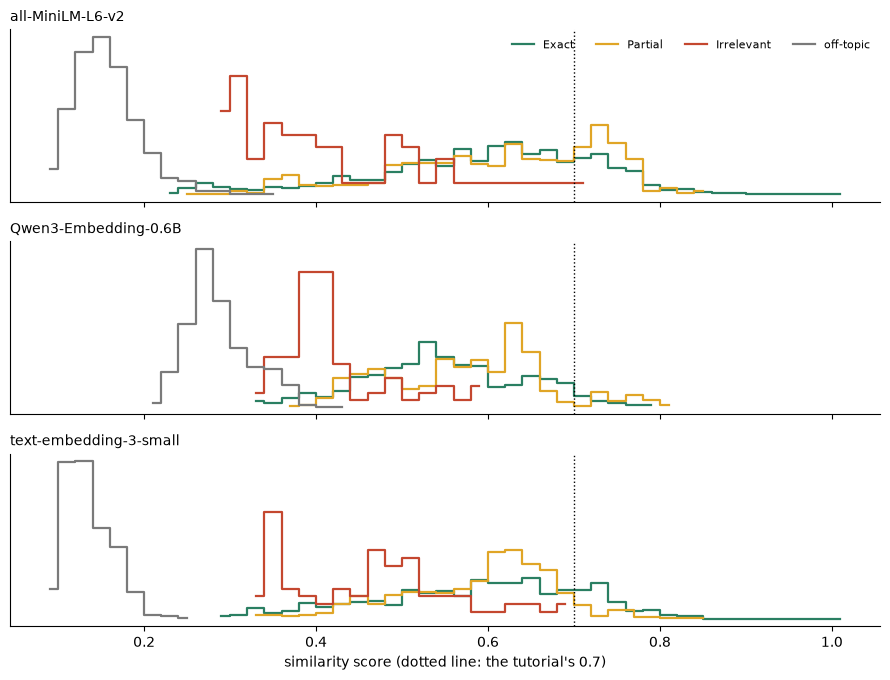

In [14]:
# Draw each model's score distribution, one colour per judgement.
import matplotlib.pyplot as plt

COLOURS = {"Exact": "#2a7f62", "Partial": "#e0a526", "Irrelevant": "#c4472f", "off-topic": "#7a7a7a"}

fig, axes = plt.subplots(len(MODELS), 1, figsize=(9, 2.3 * len(MODELS)), sharex=True, squeeze=False)
axes = axes.ravel()
for ax, name in zip(axes, MODELS):
    mine = histogram[histogram.model == name]
    for label, colour in COLOURS.items():
        part = mine[mine.label == label].sort_values("score_bin")
        # Each label as a share of its own hits, so a rare label is still visible.
        ax.step(part.score_bin + 0.01, part.hits / max(part.hits.sum(), 1), where="mid",
                color=colour, label=label, linewidth=1.6)
    ax.axvline(TUTORIAL_THRESHOLD, color="black", linestyle=":", linewidth=1)
    ax.set_title(name, loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_yticks([])
axes[0].legend(frameon=False, ncols=4, fontsize=8, loc="upper right")
axes[-1].set_xlabel("similarity score (dotted line: the tutorial's 0.7)")
plt.tight_layout()
plt.show()

For MiniLM and text-embedding-3-small, off-topic hits (grey) sit in a hump of their own, mostly clear of everything a person judged. For Qwen3-Embedding that hump runs into the bottom of the judged hits. `Exact` and `Partial` overlap almost completely for all three models. The few `Irrelevant` hits mostly score below them, but not by enough to cut on. The dotted 0.7 runs through the middle of MiniLM's judged hits and near the top of Qwen3-Embedding's.

### The products that turn up for everything

One more thing the logs show for free. Some products sit close to almost every query in a
model's space, and turn up in the top ten whatever was asked. These are called **hubs**, and
they inflate the scores a threshold sees for questions that have no good answer. Counting
them is a `GROUP BY`.

In [15]:
# Find the products each model puts in the top ten most often, across all 81 questions.
hubs = sql("""
    SELECT h.model, h.doc_id, d.text, COUNT(*) AS questions,
           SUM(CASE WHEN NOT h.on_topic THEN 1 ELSE 0 END) AS off_topic_questions
    FROM hits AS h
    JOIN documents AS d ON KEYS h.doc_id
    WHERE h.model IS NOT MISSING AND h.`rank` <= 10
    GROUP BY h.model, h.doc_id, d.text
    ORDER BY COUNT(*) DESC
""")
hubs.groupby("model").head(2).set_index(["model", "doc_id"]).reindex(list(MODELS), level=0)

off_topic_questions  questions  \
model                  doc_id                                   
all-MiniLM-L6-v2       27602                    10         10   
                       35121                     9          9   
Qwen3-Embedding-0.6B   40370                    21         21   
                       40367                    18         18   
text-embedding-3-small 30064                    13         14   
                       20070                    14         14   

                                                                                           text  
model                  doc_id                                                                    
all-MiniLM-L6-v2       27602         payden click twin daybed with trundle Daybeds & Guest Beds  
                       35121                            plenny twin daybed Daybeds & Guest Beds  
Qwen3-Embedding-0.6B   40370                         tolna california king bed Protection Plans  
                       40367                       argyros california king bed Protection Plans  
text-embedding-3-small 30064   pool lounge , floating pong table with social floating Beer Pong  
                       20070                 icer - black Ice Buckets, Beverage Tubs & Chillers

Qwen3-Embedding's hubs are near-identical *"california king bed Protection Plans"* listings: product names with almost nothing in them. Each reaches the top ten for nearly half of the 41 contract questions, and for none of the shopping queries. A hub lifts the top score of a question that has no good answer, which is exactly the score `lo` has to clear. Each model has its own hubs: daybeds for MiniLM, a beer-pong table and an ice bucket for text-embedding-3-small.

## 6. Choose a band

The fix is a **band** per model, read off that model's own distributions:

- **`lo`**: drop every hit below it. It has to sit above what off-topic questions reach and
  below what real questions reach.
- **`hi`**: above it, a hit is as good as this model's hits get. Confidence is `1`.
- **Confidence** in between is linear: `clamp((score − lo) / (hi − lo), 0, 1)`.

The band is chosen by rules, so it can be re-derived when the model changes:

- `lo` sits halfway between the strongest off-topic top score and the weakest shopping-query top
  score. Half the distance between them is the **margin**: how far a question could move before
  it lands on the wrong side. A negative margin means no single `lo` separates the two kinds of
  question.
- `hi` is the median score of a shopping query's top hit: above it, a hit scores like this
  model's typical best answer. It marks where the model's scale tops out, and promises nothing
  about relevance. Section 7 measures what the score actually knows.

Here a hit counts as right only when it is `Exact`. `Partial` (the right kind of product in the
wrong colour, say) counts as a miss, because it is not what was asked for, and because it is
most of what goes wrong: the products a person judged `Irrelevant` rarely make a modern
model's top 50 at all. That is a choice about what the filter is for, and it moves `hi`. A
pipeline that is happy to show near misses would count `Partial` as right and get a lower one.

**The band is chosen on half the questions and checked on the other half.** A threshold set and
scored on the same 81 questions would look better than it is, by exactly the amount it had
learned those questions.

In [16]:
# Split the questions in half: one half chooses each band, the other checks it.
import numpy as np

rng = np.random.default_rng(1729)
choose_ids = set(questions.groupby("on_topic").question_id.apply(
    lambda ids: rng.choice(ids, size=len(ids) // 2, replace=False)).explode())
questions["half"] = np.where(questions.question_id.isin(choose_ids), "choose", "check")

labelled = hits.merge(judgements[["question_id", "doc_id", "label"]],
                      on=["question_id", "doc_id"], how="left").merge(
    questions[["question_id", "half"]], on="question_id")
labelled.loc[~labelled.on_topic, "label"] = "off-topic"
questions.groupby(["half", "on_topic"]).size().unstack()

on_topic,False,True
half,,
check,21,20
choose,20,20


In [17]:
# Derive each model's band from the choosing half, by the rules above.
JUDGED = ["Exact", "Partial", "Irrelevant"]


def choose_band(scored):
    """lo, hi and margin from one model's labelled hits (question_id, on_topic, rank, score, label)."""
    top = scored[scored["rank"] == 1]
    strongest_off = top[~top.on_topic].score.max()
    weakest_on = top[top.on_topic].score.min()
    lo = (strongest_off + weakest_on) / 2
    hi = top[top.on_topic].score.median()
    return {"strongest off-topic": strongest_off, "weakest shopping": weakest_on,
            "lo": lo, "hi": max(hi, lo), "margin": (weakest_on - strongest_off) / 2}


bands = pd.DataFrame({name: choose_band(labelled[(labelled.model == name) & (labelled.half == "choose")])
                      for name in MODELS}).T
bands.style.format("{:.3f}").set_caption("chosen on half the questions")

,strongest off-topic,weakest shopping,lo,hi,margin
all-MiniLM-L6-v2,0.323,0.393,0.358,0.768,0.035
Qwen3-Embedding-0.6B,0.432,0.340,0.386,0.594,-0.046
text-embedding-3-small,0.254,0.428,0.341,0.733,0.087


In [18]:
# Check each band on the half of the questions it never saw.
def check_band(scored, lo):
    """What a cut at lo does to one model's hits."""
    kept = scored[scored.score >= lo]
    on = scored[scored.on_topic].question_id.nunique()
    judged = kept[kept.label.isin(JUDGED)]
    exact_all = scored[scored.label == "Exact"]
    return {
        "shopping queries left with nothing": f"{on - kept[kept.on_topic].question_id.nunique()} of {on}",
        "off-topic questions answered": f"{kept[~kept.on_topic].question_id.nunique()} of {scored[~scored.on_topic].question_id.nunique()}",
        "Exact share of judged survivors": f"{(judged.label == 'Exact').mean():.0%}",
        "Exact hits kept": f"{(exact_all.score >= lo).mean():.0%}",
    }


checked = {}
for name in MODELS:
    held_out = labelled[(labelled.model == name) & (labelled.half == "check")]
    checked[(name, f"lo = {bands.loc[name, 'lo']:.2f}")] = check_band(held_out, bands.loc[name, "lo"])
    checked[(name, f"{TUTORIAL_THRESHOLD} (tutorial)")] = check_band(held_out, TUTORIAL_THRESHOLD)
pd.DataFrame(checked).T.rename_axis(["model", "cut"])

shopping queries left with nothing  \
model                  cut                                                 
all-MiniLM-L6-v2       lo = 0.36                                 0 of 20   
                       0.7 (tutorial)                            7 of 20   
Qwen3-Embedding-0.6B   lo = 0.39                                 0 of 20   
                       0.7 (tutorial)                           16 of 20   
text-embedding-3-small lo = 0.34                                 0 of 20   
                       0.7 (tutorial)                           10 of 20   

                                      off-topic questions answered  \
model                  cut                                           
all-MiniLM-L6-v2       lo = 0.36                           0 of 21   
                       0.7 (tutorial)                      0 of 21   
Qwen3-Embedding-0.6B   lo = 0.39                           1 of 21   
                       0.7 (tutorial)                      0 of 21   
text-embedding-3-small lo = 0.34                           0 of 21   
                       0.7 (tutorial)                      0 of 21   

                                      Exact share of judged survivors  \
model                  cut                                              
all-MiniLM-L6-v2       lo = 0.36                                  55%   
                       0.7 (tutorial)                             51%   
Qwen3-Embedding-0.6B   lo = 0.39                                  53%   
                       0.7 (tutorial)                            100%   
text-embedding-3-small lo = 0.34                                  53%   
                       0.7 (tutorial)                             79%   

                                      Exact hits kept  
model                  cut                             
all-MiniLM-L6-v2       lo = 0.36                  98%  
                       0.7 (tutorial)             23%  
Qwen3-Embedding-0.6B   lo = 0.39                 100%  
                       0.7 (tutorial)              1%  
text-embedding-3-small lo = 0.34                 100%  
                       0.7 (tutorial)             17%

On the questions they never saw, the bands for MiniLM and text-embedding-3-small answer every shopping query, keep nearly all of the retrieved `Exact` hits and reject every off-topic question; 0.7 keeps between 1% and 23% of the `Exact` hits. Qwen3-Embedding's band cannot do both jobs, as its negative margin said: it lets off-topic questions through. With a negative margin `lo` has to give somewhere: raising it to stop them risks emptying shopping queries, and the rule splits the difference. The `Exact` share of the survivors hardly moves with the band. The higher shares at 0.7 come from keeping very few hits.

To see the whole trade rather than one cut, the same counts at every threshold from 0 to 1,
again in SQL++. Precision here is the `Exact` share of the judged hits a threshold keeps;
recall is the share of all retrieved `Exact` hits it keeps.

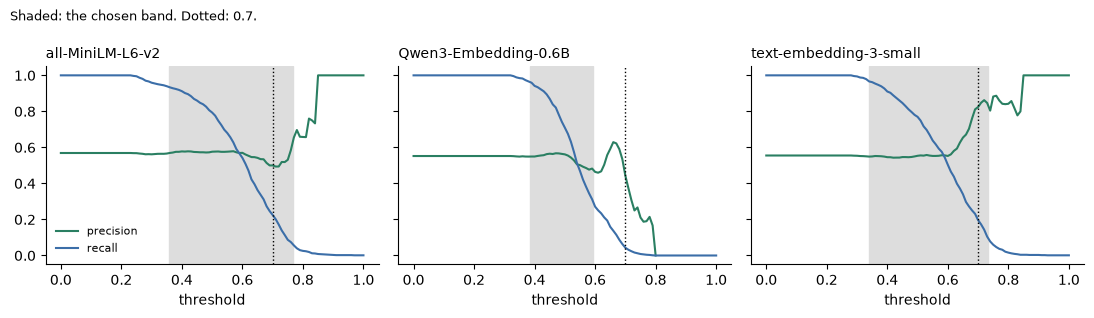

In [19]:
# Precision and recall of the kept hits at every threshold, per model, in SQL++.
curve = sql("""
    SELECT h.model, t AS threshold,
           SUM(CASE WHEN j.label = "Exact" AND h.score >= t THEN 1 ELSE 0 END) AS exact_kept,
           SUM(CASE WHEN h.score >= t THEN 1 ELSE 0 END) AS judged_kept,
           SUM(CASE WHEN j.label = "Exact" THEN 1 ELSE 0 END) AS exact_total
    FROM hits AS h
    JOIN judgements AS j ON KEYS h.question_id || "::" || h.doc_id
    UNNEST ARRAY_RANGE(0, 101) AS n
    LET t = n / 100
    WHERE h.model IS NOT MISSING AND h.on_topic
    GROUP BY h.model, t
""")
curve["precision"] = curve.exact_kept / curve.judged_kept
curve["recall"] = curve.exact_kept / curve.exact_total

fig, axes = plt.subplots(1, len(MODELS), figsize=(11, 3.2), sharey=True, squeeze=False)
axes = axes.ravel()
for ax, name in zip(axes, MODELS):
    mine = curve[curve.model == name].sort_values("threshold")
    ax.plot(mine.threshold, mine.precision, color=COLOURS["Exact"], label="precision")
    ax.plot(mine.threshold, mine.recall, color="#3b6ea8", label="recall")
    ax.axvspan(bands.loc[name, "lo"], bands.loc[name, "hi"], color="#dddddd", zorder=0)
    ax.axvline(TUTORIAL_THRESHOLD, color="black", linestyle=":", linewidth=1)
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_xlabel("threshold")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Shaded: the chosen band. Dotted: 0.7.", x=0.01, ha="left", fontsize=9)
plt.tight_layout()
plt.show()

Precision is nearly flat for all three models: about 55% of the judged hits are `Exact`, whether the cut is at 0.3 or 0.6. Recall falls steeply through each band. So within one question's results, a higher score says little about `Exact` versus `Partial`. The score's useful job is the one `lo` does: deciding whether a question has a good answer at all. Above about 0.65 the models part ways, but on few hits. Precision rises for MiniLM and text-embedding-3-small, and falls for Qwen3-Embedding.

## 7. Make a confidence mean the same thing everywhere

The band gives each hit a number between 0 and 1, and it is tempting to read that number as a
probability. It is not one. It is a straight line drawn between two cut points, and nothing
makes a band confidence of 0.6 mean the same thing for two different models.

If something downstream needs a probability (a router, a prompt that says *"only answer when
you're confident"*, a person deciding whether to trust a hit), fit one. **Isotonic
regression** learns the most faithful increasing curve from score to *probability the hit is
`Exact`*, from the judgements on the choosing half. Its only assumption is that a higher score
never means a lower chance of relevance. It is then checked on the other half, in bins of
predicted probability against how often those hits really were `Exact`.

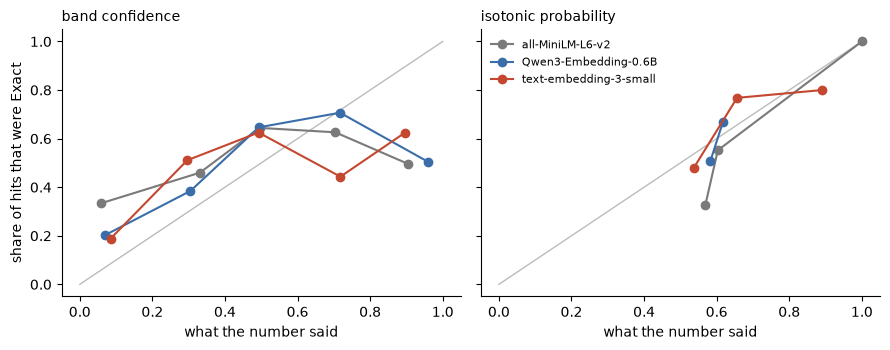

In [20]:
# Fit score -> P(Exact) per model on one half; check it on the other.
from sklearn.isotonic import IsotonicRegression

binary = labelled[labelled.label.isin(JUDGED)].assign(exact=lambda d: d.label == "Exact")
mappings, reliability = {}, []
for name in MODELS:
    mine = binary[binary.model == name]
    fit, held_out = mine[mine.half == "choose"], mine[mine.half == "check"].copy()
    mappings[name] = IsotonicRegression(out_of_bounds="clip").fit(fit.score, fit.exact)
    lo, hi = bands.loc[name, ["lo", "hi"]]
    held_out["band confidence"] = ((held_out.score - lo) / (hi - lo)).clip(0, 1)
    held_out["isotonic probability"] = mappings[name].predict(held_out.score)
    for method in ["band confidence", "isotonic probability"]:
        binned = held_out.groupby(pd.cut(held_out[method], [0, .2, .4, .6, .8, 1.0], include_lowest=True),
                                  observed=True).agg(said=(method, "mean"), was=("exact", "mean"), hits=("exact", "size"))
        reliability.append(binned.assign(model=name, method=method).reset_index(names="bin"))
reliability = pd.concat(reliability)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, method in zip(axes, ["band confidence", "isotonic probability"]):
    ax.plot([0, 1], [0, 1], color="#bbbbbb", linewidth=1)
    for (name, colour) in zip(MODELS, ["#7a7a7a", "#3b6ea8", "#c4472f", "#2a7f62", "#e0a526"]):
        r = reliability[(reliability.model == name) & (reliability.method == method)]
        ax.plot(r.said, r.was, marker="o", color=colour, label=name)
    ax.set_title(method, loc="left", fontsize=10)
    ax.set_xlabel("what the number said")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("share of hits that were Exact")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [21]:
# Brier score on the checking half: mean squared distance from the truth, lower is better.
held = binary[binary.half == "check"]
brier = {}
for name in MODELS:
    mine = held[held.model == name]
    lo, hi = bands.loc[name, ["lo", "hi"]]
    base_rate = binary[(binary.model == name) & (binary.half == "choose")].exact.mean()
    brier[name] = {
        "band confidence": float(((((mine.score - lo) / (hi - lo)).clip(0, 1) - mine.exact) ** 2).mean()),
        "isotonic probability": float(((mappings[name].predict(mine.score) - mine.exact) ** 2).mean()),
        # Knowing nothing about the hit: always say how often hits are Exact.
        "always the base rate": float(((base_rate - mine.exact) ** 2).mean()),
        "judged hits checked": len(mine),
    }
brier = pd.DataFrame(brier).T
brier.style.format({c: "{:.3f}" for c in brier.columns[:3]} | {"judged hits checked": "{:,.0f}"})

,band confidence,isotonic probability,always the base rate,judged hits checked
all-MiniLM-L6-v2,0.302,0.251,0.253,879
Qwen3-Embedding-0.6B,0.360,0.254,0.255,921
text-embedding-3-small,0.290,0.242,0.254,921


Band confidence is not a probability. Hits it placed at 0.8–1.0 were `Exact` only about half the time. The isotonic fit is honest about how little the score knows: it puts almost every hit between 0.5 and 0.65, and its Brier score lands next to the score of always guessing the base rate. Among the hits that are retrieved, the score carries little information about `Exact` versus `Partial` for any of these models. A pipeline that needs that distinction needs a reranker or a judge, not a better threshold.

## 8. The band moves when the model does

Everything above holds for one configuration of each model. Two changes that look free move
the band.

**Shorter vectors.** Some models are trained so that the first 512 or 256 numbers of a vector
are themselves a usable embedding (*Matryoshka* training). For those, shortening a vector means
keeping its first numbers and re-normalising, which is what the OpenAI-style `dimensions`
parameter does for them. So the sweep cuts the vectors it already has instead of asking the
provider again. A model not trained this way is left at full length: its first numbers are not
an embedding of anything.

**No instructions.** A model trained with an instruction on its input still produces a vector
without one. Sending the bare text is the most common mistake made with instruction-tuned
embedders, because nothing fails.

The sweep below re-derives the band, with the same rules and the same halves, for each model at
every length it can be cut to, with and without its instructions where it has any. Retrieval is
an exact nearest-neighbour search in memory over the same vectors. Section 3's hits came from
Couchbase, whose scores are the same dot products, so the full-length rows with instructions
match section 6, except where Couchbase's approximate search missed a nearest neighbour that an
exact search finds. Building a Search index for every row of a sweep is the expensive way
to answer a question that only needs the arithmetic.

In [22]:
# Embed the documents and questions once more, without instructions, for the models that use them.
plain_doc_vectors, plain_query_vectors = {}, {}
for name, m in MODELS.items():
    if not (m.query_prefix or m.document_prefix):
        continue
    plain_doc_vectors[name] = (m.embedder.encode(documents.text.tolist(), progress=True)
                               if m.document_prefix else doc_vectors[name])
    plain_query_vectors[name] = m.embedder.encode(questions.text.tolist())

In [23]:
# Re-run retrieval and re-derive the band for every model, length and instruction setting.
def exact_search(docs, queries, dims, k=K):
    """Exact top-k by cosine, after keeping the first `dims` numbers of every vector."""
    d = docs[:, :dims] / np.linalg.norm(docs[:, :dims], axis=1, keepdims=True)
    q = queries[:, :dims] / np.linalg.norm(queries[:, :dims], axis=1, keepdims=True)
    scores = q @ d.T
    top = np.argsort(-scores, axis=1)[:, :k]
    return pd.DataFrame([{"question_id": questions.question_id.iat[i], "on_topic": questions.on_topic.iat[i],
                          "rank": r + 1, "doc_id": documents.doc_id.iat[j], "score": float(scores[i, j])}
                         for i in range(len(q)) for r, j in enumerate(top[i])])


sweep = {}
for name, m in MODELS.items():
    settings_to_try = [("on", doc_vectors[name], query_vectors[name])]
    if name in plain_query_vectors:
        settings_to_try.append(("off", plain_doc_vectors[name], plain_query_vectors[name]))
    # Only models trained for it are shortened.
    native = doc_vectors[name].shape[1]
    lengths = [d for d in dict.fromkeys((native, 1024, 512, 256)) if d <= native] if m.shortenable else [native]
    for instructions, docs_v, queries_v in settings_to_try:
        for dims in lengths:
            found = exact_search(docs_v, queries_v, dims)
            run = Run("x", {qid: list(zip(g.doc_id, g.score)) for qid, g in found[found.on_topic].groupby("question_id")})
            scored = found.merge(judgements[["question_id", "doc_id", "label"]],
                                 on=["question_id", "doc_id"], how="left").merge(
                questions[["question_id", "half"]], on="question_id")
            scored.loc[~scored.on_topic, "label"] = "off-topic"
            band = choose_band(scored[scored.half == "choose"])
            sweep[(name, dims, instructions)] = {"nDCG@10": compare([run], qrels, ["nDCG@10"]).iloc[0, 0],
                                                 **{k: band[k] for k in ("lo", "hi", "margin")}}
sweep = pd.DataFrame(sweep).T.rename_axis(["model", "dims", "instructions"])
sweep.style.format("{:.3f}")

**What the index missed.** The sweep's full-length rows with instructions use the same vectors
as sections 3 to 7, searched exactly instead of through the Search index. Couchbase's vector
search is approximate: it trades a little recall for speed. Where the two disagree about a
question's best match, the index returned something other than the nearest document. Count
those questions, separately for the answerable and the unanswerable ones:

In [24]:
# For each question, did Couchbase's search return the nearest document an exact search finds?
on_topic_by_id = questions.set_index("question_id").on_topic
nearest = {}
for name in MODELS:
    exact_top = exact_search(doc_vectors[name], query_vectors[name], doc_vectors[name].shape[1], k=1)
    exact_top = exact_top.set_index("question_id").score
    index_top = hits[(hits.model == name) & (hits["rank"] == 1)].set_index("question_id").score
    drop = exact_top - index_top.reindex(exact_top.index)
    for on, kind in [(True, "shopping"), (False, "off-topic")]:
        mine = drop[on_topic_by_id.reindex(drop.index) == on]
        nearest[(name, kind)] = {"questions": len(mine), "nearest document missed": int((mine > 1e-4).sum()),
                                 "largest drop in top score": float(mine.max())}
nearest = pd.DataFrame(nearest).T.rename_axis(["model", "questions"])
nearest.style.format({"questions": "{:.0f}", "nearest document missed": "{:.0f}",
                      "largest drop in top score": "{:.3f}"})

Dropping Qwen3-Embedding's instruction costs about 0.08 nDCG@10 and moves its whole band up by about 0.25, `lo` from 0.39 to 0.62. Its margin even turns positive, but its ranking is worse: separating questions and ranking answers are different jobs. A band measured with the instruction, applied to vectors made without it, would let off-topic questions through. Shortening moves `lo` up too: for text-embedding-3-small, from 0.35 at 1,536 dimensions to 0.42 at 256, at almost no cost in nDCG@10. Neither change raises an error.

The index rarely misses for a shopping query, and misses for many of the contract questions. A question with no good answer has no near neighbour to find, only many documents at roughly the same distance, which is probably where an approximate search is weakest. A miss lowers an unanswerable question's top score, so the band chosen from the index's hits is more optimistic than the model's own geometry. That is still the right band for the index that serves the queries. But which questions an approximate index misses depends on how it was built, so re-check the band whenever the index is rebuilt.

## Where to take this

- **Store the band with the model.** A threshold belongs to a model, a length, a prompt
  format and an index build, so keep it as a document beside the vectors it was measured on, and refuse to search
  with a band measured on something else. Change the model and the band is re-derived, not
  carried over.
- **Gate the answer, not just the hits.** In a RAG pipeline, `lo` is what stops a chat model
  writing a confident answer from loosely related documents. With no hits above it, the
  honest reply is *"nothing in here answers that"*, and [`flows/01`](../flows/01_rag_that_you_can_trust.ipynb)
  measures how often a model invents one instead.
- **Calibrate the hybrid.** BM25 scores are not bounded at all, and a hybrid search adds them to
  cosines. The same logs and the same SQL++ give a hybrid score its own band.
- **Try other languages.** A question asked in another language can score far lower against
  the same product than its translation does, by an amount that differs between models. If
  your users write in more than one language, measure the band per language.
- **Run it on your own corpus.** Section 1 names the three tables everything else reads, and
  section 2 is where the models you are choosing between go. A few hundred hits with a person's
  verdict on each are enough to choose a band this way.

## What produced these results

Every number above came from the models below. A different model, or the same name served
differently, will give different numbers.

In [25]:
# Name the models that produced the results above.
cbnb.run_card()

,model,how it ran
Embeddings,Qwen/Qwen3-Embedding-0.6B,"via NanoGPT; 6,644 texts, 6,644 from cache"
Embeddings,sentence-transformers/all-MiniLM-L6-v2,"on this machine; 6,563 texts, 6,563 from cache"
Embeddings,text-embedding-3-small,"via NanoGPT; 6,563 texts, 6,563 from cache"


In [26]:
# Optional clean-up: delete what this notebook created. Uncomment to run.
# from cbnb.couchbase_io import drop_demo_data
# drop_demo_data(cluster, BUCKET, SCOPE)